# Módulo 3 — Clasificador supervisado con TF-IDF (AG News)

Pipeline de clasificación de noticias en 4 categorías usando NLP clásico:

1. Reutiliza el corpus preprocesado del Módulo 2 (`salidas/*_preprocesado.csv`).
2. Vectoriza con **TF-IDF** ajustando **solo sobre train**.
3. Entrena tres baselines: Naive Bayes, SVM lineal y Regresión Logística.
4. Evalúa con Precision, Recall, F1 y matriz de confusión multiclase.

**Dataset:** AG News — 8.000 train / 2.000 test, 4 clases balanceadas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (7, 5)

## 1. Carga del corpus preprocesado (Módulo 2)

Se usan los CSV generados por `pipeline_eda.py`, que ya contienen la columna `clean`
(limpieza regex + lematización + stop-words). Si no existen, ejecutar antes:
`python pipeline_eda.py`.

In [2]:
train_df = pd.read_csv("salidas/ag_news_train_preprocesado.csv")
test_df = pd.read_csv("salidas/ag_news_test_preprocesado.csv")

X_train, y_train = train_df["clean"].fillna(""), train_df["label"]
X_test, y_test = test_df["clean"].fillna(""), test_df["label"]

print(f"Train: {train_df.shape} | Test: {test_df.shape}")
print(f"Clases (orden sklearn): {sorted(y_train.unique())}")
train_df["label"].value_counts()

Train: (8000, 3) | Test: (2000, 3)
Clases (orden sklearn): ['Business', 'Sci_Tech', 'Sports', 'World']


label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64

## 2. Separación train/test y prevención de Data Leakage

`fit_transform()` se aplica **únicamente** sobre `X_train`.
Sobre `X_test` se usa solo `transform()`, de modo que el vocabulario y los IDF
se aprenden exclusivamente con datos de entrenamiento.

## 3. Experimentos de TF-IDF (`max_features` y `ngram_range`)

La configuración se elige por **validación cruzada (3 folds) sobre train**.
El vectorizador va dentro del `Pipeline`, así que cada fold ajusta su propio
vocabulario y no hay fuga de información. El test no participa en la selección.

In [3]:
configs = [
    (5000, (1, 1)),
    (10000, (1, 1)),
    (5000, (1, 2)),
    (10000, (1, 2)),
    (20000, (1, 2)),
]

filas = []
for max_features, ngram_range in configs:
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=max_features, ngram_range=ngram_range,
                                  stop_words="english", min_df=2, max_df=0.95)),
        ("clf", LogisticRegression(max_iter=10000, random_state=42)),
    ])
    cv = cross_val_score(pipe, X_train, y_train, cv=3, scoring="f1_macro")
    pipe.fit(X_train, y_train)
    filas.append({
        "max_features": max_features,
        "ngram_range": str(ngram_range),
        "vocabulario": len(pipe.named_steps["tfidf"].vocabulary_),
        "CV F1 Macro": round(cv.mean(), 4),
        "CV std": round(cv.std(), 4),
    })

experimentos = pd.DataFrame(filas).sort_values("CV F1 Macro", ascending=False)
experimentos

,max_features,ngram_range,vocabulario,CV F1 Macro,CV std
4,20000,"(1, 2)",20000,0.8823,0.0042
3,10000,"(1, 2)",10000,0.8816,0.0048
1,10000,"(1, 1)",9093,0.8793,0.0032
2,5000,"(1, 2)",5000,0.8789,0.0042
0,5000,"(1, 1)",5000,0.8782,0.0034


In [4]:
# Configuración ganadora: (1,2) con 20k features
vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2),
                             stop_words="english", min_df=2, max_df=0.95)

X_train_vec = vectorizer.fit_transform(X_train)   # SOLO train
X_test_vec = vectorizer.transform(X_test)         # test: solo transform

print(f"Matriz train: {X_train_vec.shape}")
print(f"Matriz test : {X_test_vec.shape}")

Matriz train: (8000, 20000)
Matriz test : (2000, 20000)


## 4. Entrenamiento de los tres baselines

In [5]:
modelos = {
    "Naive Bayes": MultinomialNB(),
    "SVM lineal": LinearSVC(max_iter=10000, random_state=42),
    "Regresión Logística": LogisticRegression(max_iter=10000, random_state=42),
}

resultados, predicciones = [], {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_vec, y_train)
    y_pred = modelo.predict(X_test_vec)
    predicciones[nombre] = y_pred
    resultados.append({
        "Modelo": nombre,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "F1 Macro": round(f1_score(y_test, y_pred, average="macro"), 4),
        "F1 Weighted": round(f1_score(y_test, y_pred, average="weighted"), 4),
    })

resumen = pd.DataFrame(resultados).sort_values("F1 Macro", ascending=False)
resumen

,Modelo,Accuracy,F1 Macro,F1 Weighted
0,Naive Bayes,0.8965,0.8967,0.8967
2,Regresión Logística,0.8925,0.8926,0.8926
1,SVM lineal,0.8895,0.8897,0.8897


## 5. Evaluación detallada del mejor modelo

In [6]:
mejor = resumen.iloc[0]["Modelo"]
y_pred = predicciones[mejor]
print(f"Mejor modelo: {mejor}\n")
print(classification_report(y_test, y_pred, digits=3))

Mejor modelo: Naive Bayes

              precision    recall  f1-score   support

    Business      0.830     0.872     0.851       500
    Sci_Tech      0.889     0.866     0.877       500
      Sports      0.954     0.964     0.959       500
       World      0.915     0.884     0.899       500

    accuracy                          0.896      2000
   macro avg      0.897     0.896     0.897      2000
weighted avg      0.897     0.896     0.897      2000



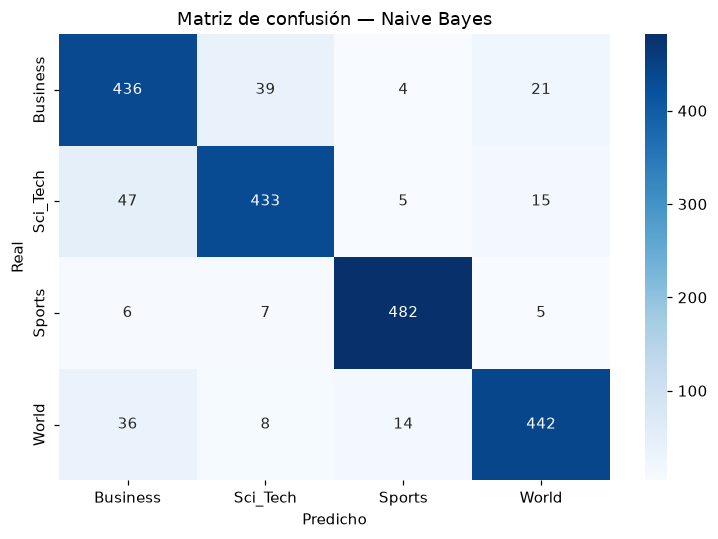

In [7]:
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title(f"Matriz de confusión — {mejor}")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

In [8]:
reporte = classification_report(y_test, y_pred, output_dict=True)
analisis = pd.DataFrame({
    clase: {
        "precision": round(reporte[clase]["precision"], 3),
        "recall": round(reporte[clase]["recall"], 3),
        "f1-score": round(reporte[clase]["f1-score"], 3),
        "support": int(reporte[clase]["support"]),
    }
    for clase in labels
}).T

analisis.sort_values("f1-score")

,precision,recall,f1-score,support
Business,0.830,0.872,0.851,500.0
Sci_Tech,0.889,0.866,0.877,500.0
World,0.915,0.884,0.899,500.0
Sports,0.954,0.964,0.959,500.0


## 6. Interpretación: términos más relevantes por clase

Coeficientes positivos más altos del modelo de Regresión Logística.

In [9]:
lr = modelos["Regresión Logística"]
nombres = vectorizer.get_feature_names_out()

for i, clase in enumerate(lr.classes_):
    top = nombres[np.argsort(lr.coef_[i])[-10:]][::-1]
    print(f"{clase:9s}: " + ", ".join(top))

Business : company, profit, oil, billion, buy, economy, share, corp, fund, price
Sci_Tech : internet, space, software, scientist, microsoft, computer, nasa, technology, online, phone
Sports   : team, coach, win, game, season, cup, league, player, night, olympic
World    : iraq, president, kill, leader, minister, nuclear, election, rebel, military, israel


## 7. Conclusiones

- **Naive Bayes** obtiene el mejor F1 Macro (~0.90) sobre el test, con un costo computacional mínimo.
- **Business** es la clase más difícil: se confunde con **Sci/Tech** (empresas tecnológicas)
  y con **World** (economía internacional).
- **Sports** es la clase más separable gracias a un vocabulario muy específico.
- Usar **unigramas + bigramas** y 20k features mejora el F1 frente a unigramas con vocabulario reducido.
- El flujo respeta el rigor estadístico: vocabulario ajustado solo en train,
  hiperparámetros elegidos por validación cruzada y test reservado para la evaluación final.